# Heart Disease Data - Exploratory Data Analysis (EDA)
**Pulse of Prevention: Analyzing Heart Health for Better Outcomes**

**Prepared by:** Shubham Shah  
**Tools used:** Python, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn

## Project Overview
I am working as a data analyst at **HealthPulse Analytics**. The company received a dataset of patients from a cardiology research institute and wants to understand the factors linked with heart disease, find the profile of high-risk patients, and suggest preventive measures.

**What I want to find out**
1. What do the patients in the data look like (age, sex, blood pressure, cholesterol and so on)?
2. Which factors are most related to heart disease?
3. Can a simple model predict heart disease from these measurements?
4. What can doctors and the company do with these findings?

**Dataset:** Heart Disease Dataset (Kaggle) - `heart.csv`  
Keep the csv file in the same folder as this notebook (or change the path in the load cell).

**Columns:** `age`, `sex` (1 = male, 0 = female), `cp` (chest pain type 0-3), `trestbps` (resting blood pressure), `chol` (cholesterol), `fbs` (fasting blood sugar > 120: 1 = yes), `restecg` (resting ECG 0-2), `thalach` (maximum heart rate), `exang` (exercise-induced angina: 1 = yes), `oldpeak` (ST depression), `slope` (ST slope 0-2), `ca` (major vessels 0-3), `thal` (thalassemia: 1 = normal, 2 = fixed defect, 3 = reversible defect), `target` (heart disease: 1 = yes, 0 = no).

## Step 1: Import Libraries and Load the Data

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('heart.csv')

## Step 2: Understanding the Data

In [7]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [8]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


In [9]:
df.shape

(1025, 14)

In [10]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [12]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## Step 3: Data Cleaning
Order of cleaning: missing values, duplicates, invalid codes, data types, outliers, normalization.

### 3.1 Missing values

In [15]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

There are no missing values in any column.

### 3.2 Duplicate rows

In [18]:
df.duplicated().sum()

723

**723 out of 1,025 rows are duplicates.** That is a very large number. If I keep them, the same patients are counted again and again and every average and percentage becomes wrong, so I remove them.

In [20]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(302, 14)

In [21]:
df['target'].value_counts()

target
1    164
0    138
Name: count, dtype: int64

After removing the duplicates, **302 unique patients** are left. The data is quite balanced: 164 patients have target = 1 and 138 have target = 0, so I do not need to do any balancing later.

### 3.3 Checking the codes
The data dictionary says `thal` should be 1 to 3 and `ca` should be 0 to 3. Let me check if all values are valid.

In [24]:
print(df['thal'].value_counts().sort_index())
print()
print(df['ca'].value_counts().sort_index())

thal
0      2
1     18
2    165
3    117
Name: count, dtype: int64

ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64


In [25]:
# thal = 0 and ca = 4 are not valid codes (only a handful of rows), so I replace them
# with the most common value of the column
df.loc[df['thal'] == 0, 'thal'] = df['thal'].mode()[0]
df.loc[df['ca'] == 4, 'ca'] = df['ca'].mode()[0]

### 3.4 Data types

In [27]:
df.dtypes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

All columns are already numeric, so no conversion is needed. But columns like `sex`, `cp`, `exang` are codes and not real numbers, so I add a readable label for sex and for the age group, which will be useful in the charts.

In [29]:
df['sex_label'] = df['sex'].map({1: 'Male', 0: 'Female'})

df['age_group'] = pd.cut(df['age'], bins=[0, 39, 49, 59, 100],
                         labels=['Under 40', '40-49', '50-59', '60 and above'])
df[['age', 'age_group', 'sex', 'sex_label']].head()

,age,age_group,sex,sex_label
0,52,50-59,1,Male
1,53,50-59,1,Male
2,70,60 and above,1,Male
3,61,60 and above,1,Male
4,62,60 and above,0,Female


### 3.5 Outliers
I use the IQR method (values far below Q1 or far above Q3) on the numerical clinical columns.

In [31]:
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df[col] < low) | (df[col] > high)).sum()
    print(col, '-> outliers:', count)

age -> outliers: 0
trestbps -> outliers: 9
chol -> outliers: 5
thalach -> outliers: 1
oldpeak -> outliers: 5


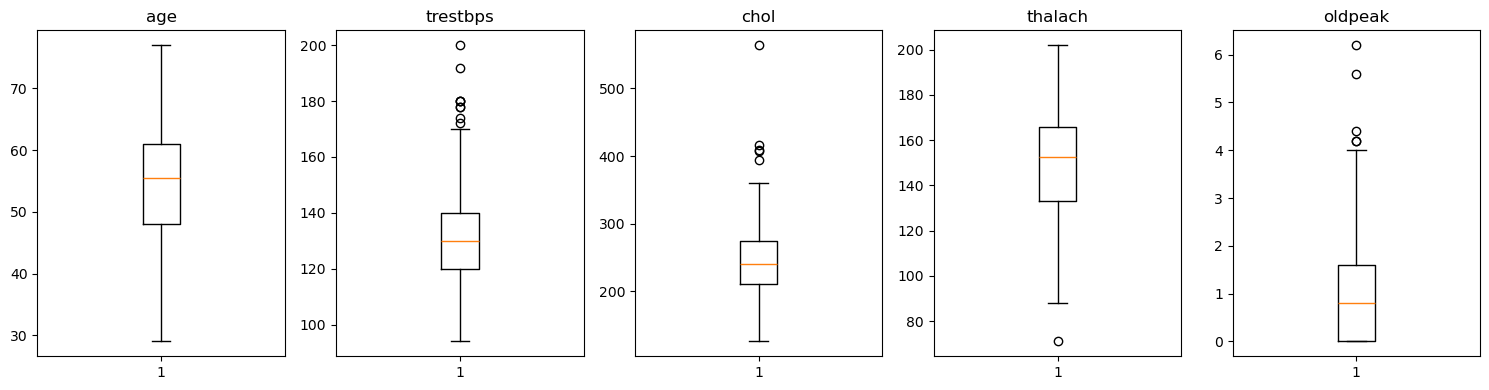

In [32]:
fig, ax = plt.subplots(1, 5, figsize=(15, 4))
for i, col in enumerate(num_cols):
    ax[i].boxplot(df[col])
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

There are only a few outliers (for example a cholesterol of 564 or a very high ST depression). I decided to **keep them**. These are real medical readings of real patients, and the patients with extreme values are exactly the high-risk patients this study wants to find, so removing them would hide the important cases.

### 3.6 Normalization

The clinical measurements are on very different scales (cholesterol is around 250 but oldpeak is around 1). I create a separate normalized copy (min-max scaling, 0 to 1) so that they can be compared on the same chart. The original data stays unchanged for the other questions.

In [36]:
df_norm = df.copy()
for col in num_cols:
    df_norm[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())

df_norm[num_cols].describe().loc[['min', 'max']]

,age,trestbps,chol,thalach,oldpeak
min,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0


The data is clean now. We started with **1,025** rows and are left with **302** unique patients and 14 original columns.

### 3.7 A quick check on the target column
Before the analysis, I compared a few well-known heart disease signs for the two target groups. In normal medical knowledge, patients with heart disease usually have **lower** maximum heart rate, **more** exercise-induced angina, **higher** ST depression (oldpeak) and **more** blocked vessels (ca).

In [39]:
df.groupby('target')[['thalach', 'exang', 'oldpeak', 'ca']].mean().round(2)

,thalach,exang,oldpeak,ca
target,,,,
0,139.10,0.55,1.59,1.14
1,158.38,0.14,0.59,0.27


**Important note:** In this data it is the other way round - the group with **target = 1** has a *higher* maximum heart rate (158 vs 139), *less* angina (14% vs 55%), *lower* oldpeak and *fewer* blocked vessels. This suggests that the `target` column may be coded the opposite way from the data dictionary (1 = no disease). This is a known issue with this Kaggle dataset.

In this notebook I follow the data dictionary given in the case study (target = 1 means heart disease), but I describe the groups as **"target = 1"** in the insights and I mention this limitation again in the conclusion. If the coding is confirmed to be reversed, all the "heart disease" conclusions below would simply swap sides.

# Basic Level Questions

## Basic Q1. What is the average age of patients in the dataset?

In [43]:
avg_age = df['age'].mean()
print('Average age:', round(avg_age, 1))
print('Youngest:', df['age'].min(), '| Oldest:', df['age'].max())

Average age: 54.4
Youngest: 29 | Oldest: 77


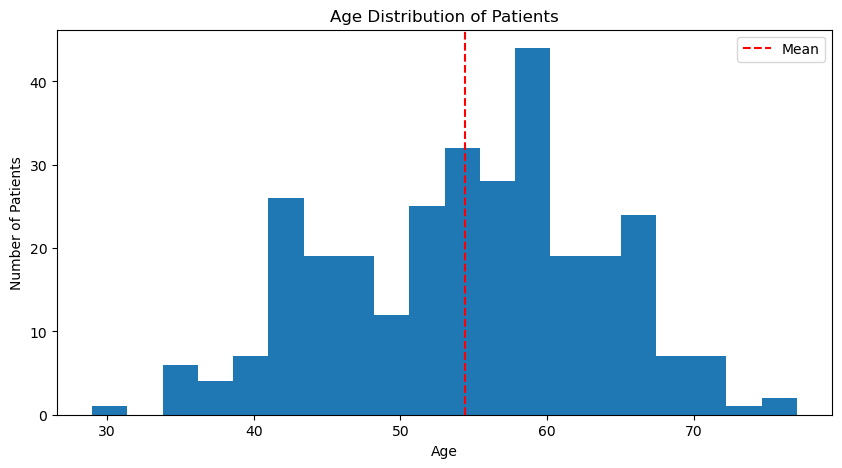

In [44]:
plt.figure(figsize=(10,5))
plt.hist(df['age'], bins=20)
plt.axvline(avg_age, color='red', linestyle='--', label='Mean')
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.legend()
plt.show()

**Insight:** The average age is **54.4 years** (from 29 to 77), and most patients are between 48 and 61. These are mostly middle-aged and older people, so preventive programs should focus on people aged 50 and above.

## Basic Q2. What is the gender distribution of patients?

In [47]:
gender_count = df['sex_label'].value_counts()
gender_count

sex_label
Male      206
Female     96
Name: count, dtype: int64

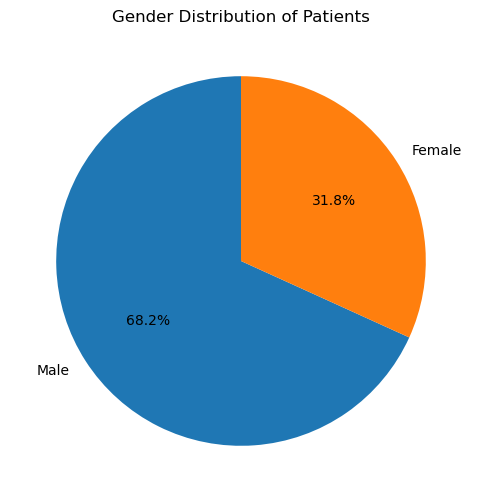

In [48]:
plt.figure(figsize=(6,6))
plt.pie(gender_count.values, labels=gender_count.index, autopct='%1.1f%%', startangle=90)
plt.title('Gender Distribution of Patients')
plt.show()

**Insight:** **206 patients (68%) are male** and 96 (32%) are female. The data has about twice as many men as women, so any gender comparison should be read with this in mind.

## Basic Q3. What is the average resting blood pressure of patients?

In [51]:
avg_bp = df['trestbps'].mean()
print('Average resting blood pressure:', round(avg_bp, 1), 'mm Hg')
print('Median:', df['trestbps'].median())

Average resting blood pressure: 131.6 mm Hg
Median: 130.0


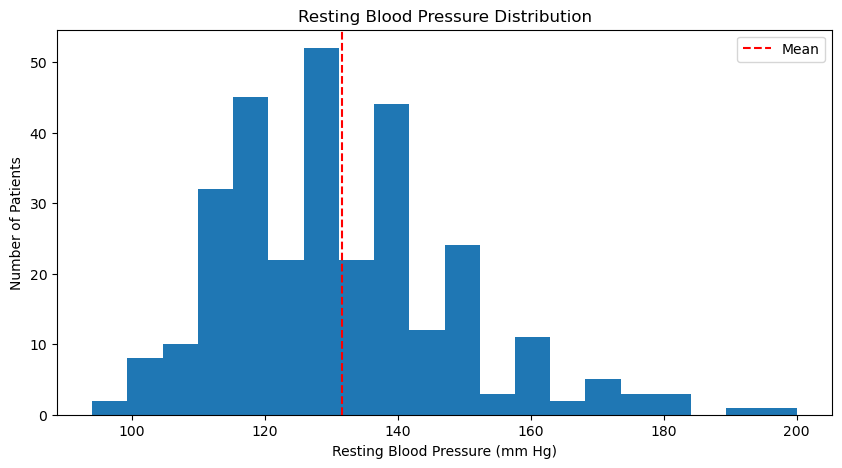

In [52]:
plt.figure(figsize=(10,5))
plt.hist(df['trestbps'], bins=20)
plt.axvline(avg_bp, color='red', linestyle='--', label='Mean')
plt.title('Resting Blood Pressure Distribution')
plt.xlabel('Resting Blood Pressure (mm Hg)')
plt.ylabel('Number of Patients')
plt.legend()
plt.show()

**Insight:** The average resting blood pressure is **131.6 mm Hg**. A normal level is about 120, so the average patient is already above normal. **32%** of patients have a blood pressure of 140 or more (high blood pressure range).

## Basic Q4. How many patients have fasting blood sugar higher than 120 mg/dl?

In [55]:
high_fbs = df['fbs'].sum()
print('Patients with high fasting blood sugar:', high_fbs)
print('Percentage:', round(high_fbs / len(df) * 100, 1), '%')

Patients with high fasting blood sugar: 45
Percentage: 14.9 %


**Insight:** **45 patients (14.9%)** have a fasting blood sugar above 120 mg/dl. It is a smaller group, but these patients need diet and lifestyle advice because high blood sugar is a known risk factor.

## Basic Q5. What are the different types of chest pain recorded in the dataset?

In [58]:
print('Chest pain types:', sorted(df['cp'].unique()))
cp_count = df['cp'].value_counts().sort_index()
cp_count

Chest pain types: [0, 1, 2, 3]


cp
0    143
1     50
2     86
3     23
Name: count, dtype: int64

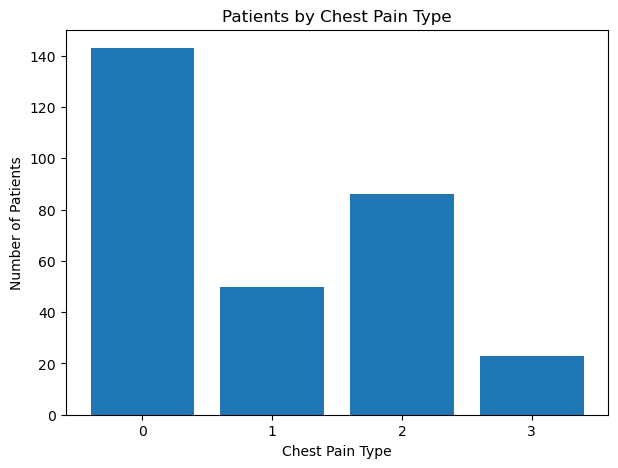

In [59]:
plt.figure(figsize=(7,5))
plt.bar(cp_count.index.astype(str), cp_count.values)
plt.title('Patients by Chest Pain Type')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')
plt.show()

**Insight:** There are **4 chest pain types (0, 1, 2 and 3)**. Type 0 is the most common with **143 patients (47%)**, followed by type 2 (86) and type 1 (50). Type 3 is rare (23 patients).

## Basic Q6. What is the maximum heart rate achieved by patients?

In [62]:
print('Maximum heart rate achieved:', df['thalach'].max())
print('Average maximum heart rate :', round(df['thalach'].mean(), 1))
print('Lowest maximum heart rate  :', df['thalach'].min())

Maximum heart rate achieved: 202
Average maximum heart rate : 149.6
Lowest maximum heart rate  : 71


In [63]:
df[df['thalach'] == df['thalach'].max()][['age', 'sex_label', 'thalach', 'target']]

,age,sex_label,thalach,target
56,29,Male,202,1


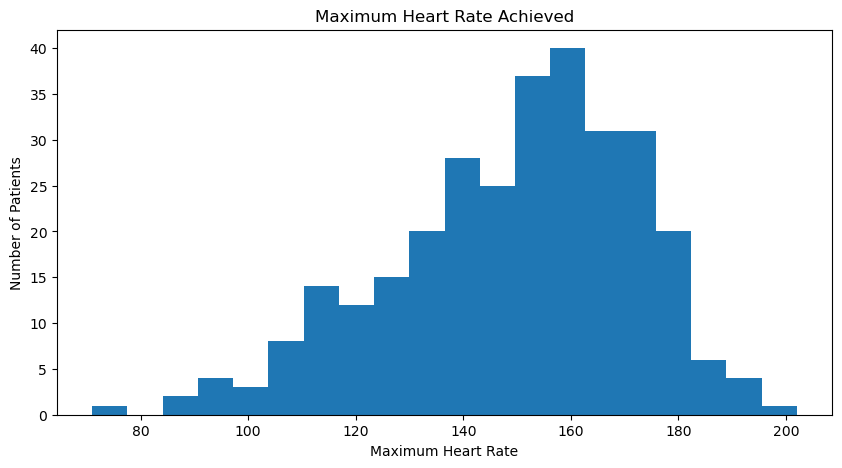

In [64]:
plt.figure(figsize=(10,5))
plt.hist(df['thalach'], bins=20)
plt.title('Maximum Heart Rate Achieved')
plt.xlabel('Maximum Heart Rate')
plt.ylabel('Number of Patients')
plt.show()

**Insight:** The highest heart rate reached is **202 bpm** and the average is 150 bpm. The highest value was reached by a 29-year-old patient. Exercise programs for patients should stay well below the individual's maximum.

## Basic Q7. What percentage of patients experience exercise-induced angina?

In [67]:
angina_pct = df['exang'].mean() * 100
print('Patients with exercise-induced angina:', round(angina_pct, 1), '%')

Patients with exercise-induced angina: 32.8 %


**Insight:** **32.8%** of patients (99 patients) get chest pain during exercise. About 1 in 3 patients needs a careful, supervised exercise plan.

## Basic Q8. What is the average cholesterol level in the dataset?

In [70]:
avg_chol = df['chol'].mean()
print('Average cholesterol:', round(avg_chol, 1), 'mg/dl')
print('Median:', df['chol'].median())

Average cholesterol: 246.5 mg/dl
Median: 240.5


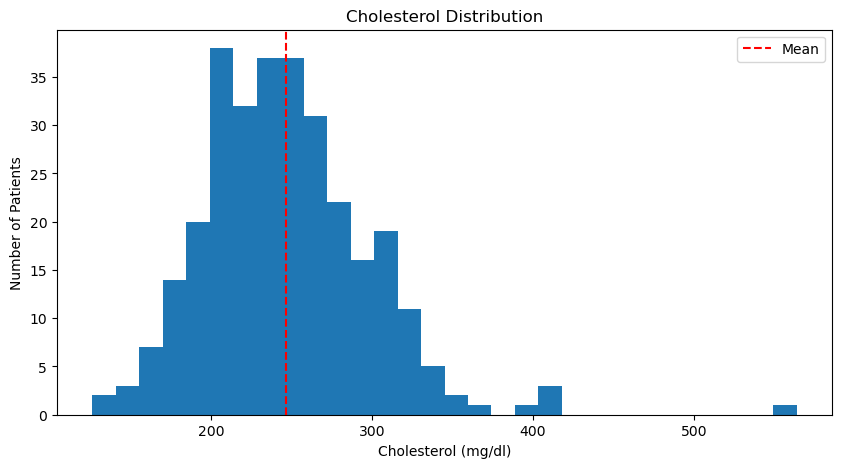

In [71]:
plt.figure(figsize=(10,5))
plt.hist(df['chol'], bins=30)
plt.axvline(avg_chol, color='red', linestyle='--', label='Mean')
plt.title('Cholesterol Distribution')
plt.xlabel('Cholesterol (mg/dl)')
plt.ylabel('Number of Patients')
plt.legend()
plt.show()

**Insight:** The average cholesterol is **246.5 mg/dl**. A healthy level is under 200, so the average patient is well above it, and **51%** of patients have 240 or more (high range). Cholesterol control is clearly an important area for this group.

## Basic Q9. How many patients have a resting electrocardiographic result of 2?

In [74]:
restecg_count = df['restecg'].value_counts().sort_index()
restecg_count

restecg
0    147
1    151
2      4
Name: count, dtype: int64

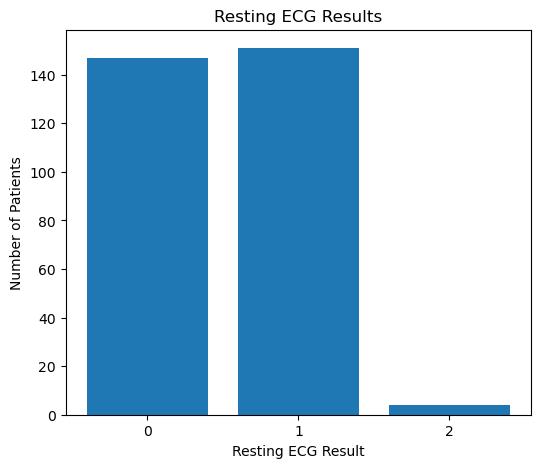

In [75]:
plt.figure(figsize=(6,5))
plt.bar(restecg_count.index.astype(str), restecg_count.values)
plt.title('Resting ECG Results')
plt.xlabel('Resting ECG Result')
plt.ylabel('Number of Patients')
plt.show()

**Insight:** Only **4 patients** have a resting ECG result of 2, which is a very small group (1%). Most patients have result 0 (147) or 1 (151). Because result 2 is so rare, no strong conclusions can be drawn about it.

## Basic Q10. What is the distribution of the number of major vessels colored by fluoroscopy?

In [78]:
ca_count = df['ca'].value_counts().sort_index()
ca_count

ca
0    179
1     65
2     38
3     20
Name: count, dtype: int64

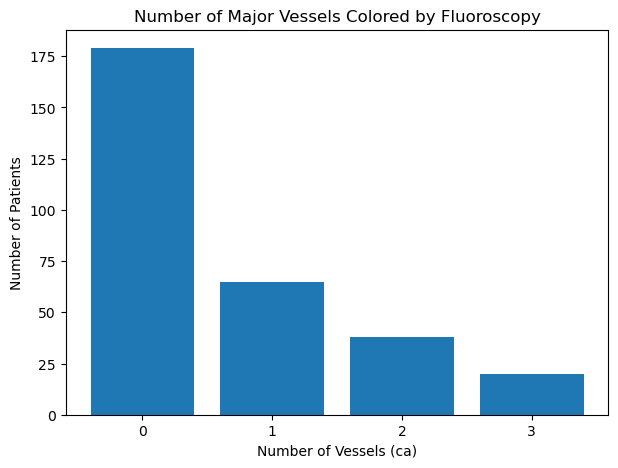

In [79]:
plt.figure(figsize=(7,5))
plt.bar(ca_count.index.astype(str), ca_count.values)
plt.title('Number of Major Vessels Colored by Fluoroscopy')
plt.xlabel('Number of Vessels (ca)')
plt.ylabel('Number of Patients')
plt.show()

**Insight:** **179 patients (59%)** have 0 vessels colored, and the number falls as the number of vessels goes up (65 with 1, 38 with 2 and 20 with 3). Patients with 2 or 3 vessels (58 patients) are the most serious cases and should get priority care.

# Medium Level Questions

## Medium Q1. What is the correlation between age and cholesterol levels?

In [83]:
df[['age', 'chol']].corr()

,age,chol
age,1.000000,0.207216
chol,0.207216,1.000000


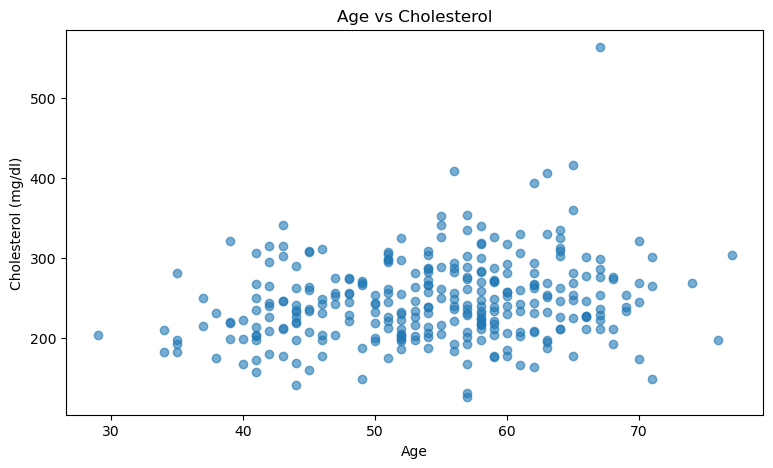

In [84]:
plt.figure(figsize=(9,5))
plt.scatter(df['age'], df['chol'], alpha=0.6)
plt.title('Age vs Cholesterol')
plt.xlabel('Age')
plt.ylabel('Cholesterol (mg/dl)')
plt.show()

In [85]:
# average cholesterol in each age group
chol_age = df.groupby('age_group', observed=True)['chol'].mean()
chol_age

age_group
Under 40        218.733333
40-49           235.847222
50-59           247.424000
60 and above    258.366667
Name: chol, dtype: float64

**Insight:** The correlation between age and cholesterol is **0.21**, a weak positive link - cholesterol goes up slightly with age, but age explains very little of it. The scatter plot has no clear pattern. Average cholesterol by age group goes from 219 for the youngest to 258 for the oldest, so cholesterol checks are needed at every age, not only for older patients.

## Medium Q2. What is the distribution of chest pain types across different age groups?

Using each exact age would give a very messy chart, so I use the age groups I created earlier.

In [89]:
cp_age = pd.crosstab(df['age_group'], df['cp'])
cp_age

cp,0,1,2,3
age_group,,,,
Under 40,4,3,6,2
40-49,28,19,22,3
50-59,61,21,34,9
60 and above,50,7,24,9


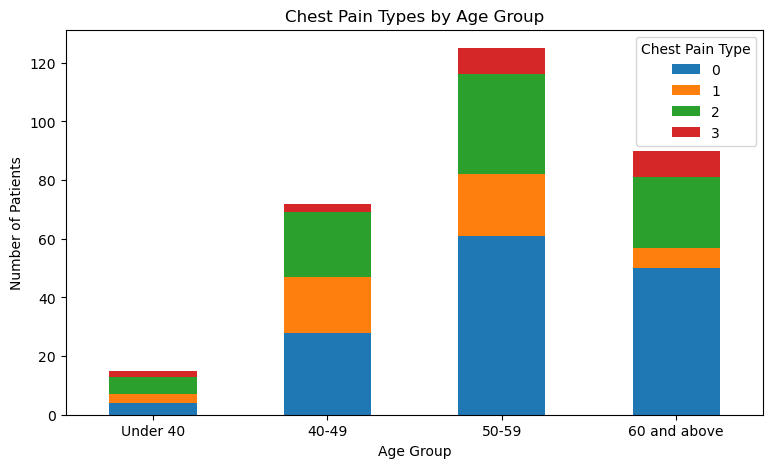

In [90]:
cp_age.plot(kind='bar', stacked=True, figsize=(9,5))
plt.title('Chest Pain Types by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(title='Chest Pain Type')
plt.show()

In [91]:
# same thing in percentage for each age group
(pd.crosstab(df['age_group'], df['cp'], normalize='index') * 100).round(1)

cp,0,1,2,3
age_group,,,,
Under 40,26.7,20.0,40.0,13.3
40-49,38.9,26.4,30.6,4.2
50-59,48.8,16.8,27.2,7.2
60 and above,55.6,7.8,26.7,10.0


**Insight:** Chest pain type 0 gets more common as age goes up: it is **27%** of patients under 40, 39% of the 40-49 group, 49% of the 50-59 group and **56%** of patients aged 60 and above. Younger patients (under 40) mostly report type 2 (40%). The 50-59 group has the most patients overall (125). So the type of chest pain changes with age, and diagnosis protocols can be adjusted for each age group.

## Medium Q3. How does maximum heart rate vary with exercise-induced angina?

In [94]:
hr_exang = df.groupby('exang')['thalach'].mean()
hr_exang.index = ['No Angina', 'Angina']
hr_exang

No Angina    155.596059
Angina       137.212121
Name: thalach, dtype: float64

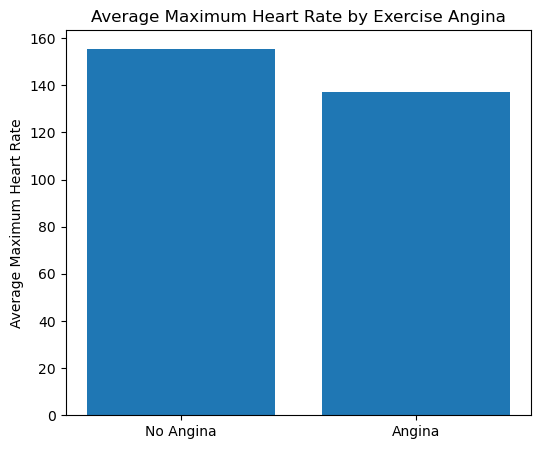

In [95]:
plt.figure(figsize=(6,5))
plt.bar(hr_exang.index, hr_exang.values)
plt.title('Average Maximum Heart Rate by Exercise Angina')
plt.ylabel('Average Maximum Heart Rate')
plt.show()

**Insight:** Patients **without** angina reach a higher maximum heart rate (**156 bpm**) than patients **with** angina (**137 bpm**), a difference of about 18 bpm. Patients who get angina during exercise cannot push their heart rate as high, so they need lower intensity exercise plans.

## Medium Q4. Is there a significant difference in resting blood pressure between male and female patients?

In [98]:
bp_sex = df.groupby('sex_label')['trestbps'].mean()
bp_sex

sex_label
Female    133.083333
Male      130.912621
Name: trestbps, dtype: float64

In [99]:
from scipy import stats

male_bp = df[df['sex'] == 1]['trestbps']
female_bp = df[df['sex'] == 0]['trestbps']

t_stat, p_value = stats.ttest_ind(male_bp, female_bp)
print('t-statistic:', round(t_stat, 3))
print('p-value    :', round(p_value, 4))

t-statistic: -1.0
p-value    : 0.318


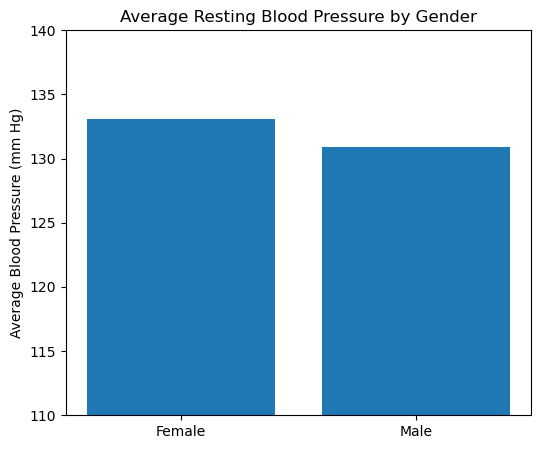

In [100]:
plt.figure(figsize=(6,5))
plt.bar(bp_sex.index, bp_sex.values)
plt.title('Average Resting Blood Pressure by Gender')
plt.ylabel('Average Blood Pressure (mm Hg)')
plt.ylim(110, 140)
plt.show()

**Insight:** Women have an average blood pressure of 133.1 and men have 130.9. The t-test gives a p-value of **0.318**, which is **above 0.05**, so the difference is **not statistically significant**. So men and women have about the same blood pressure here, and the same advice can be given to both.

## Medium Q5. What is the relationship between fasting blood sugar levels and the presence of heart disease?

In [103]:
fbs_target = pd.crosstab(df['fbs'], df['target'])
fbs_target

target,0,1
fbs,,
0,116,141
1,22,23


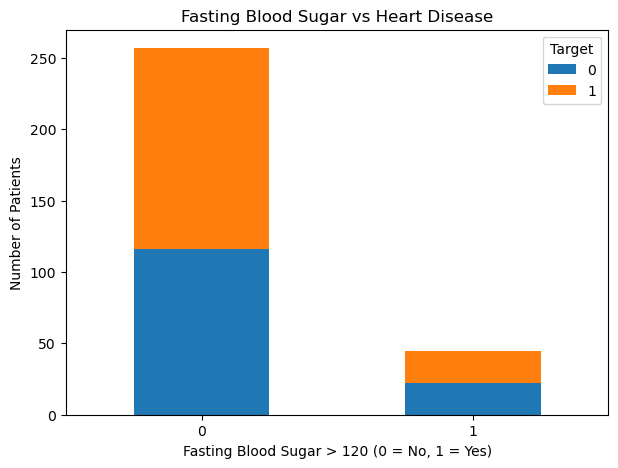

In [104]:
fbs_target.plot(kind='bar', stacked=True, figsize=(7,5))
plt.title('Fasting Blood Sugar vs Heart Disease')
plt.xlabel('Fasting Blood Sugar > 120 (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(title='Target')
plt.show()

In [105]:
# percentage of target = 1 in each fbs group
df.groupby('fbs')['target'].mean() * 100

fbs
0    54.863813
1    51.111111
Name: target, dtype: float64

**Insight:** The share of patients with target = 1 is **55%** among patients with normal fasting blood sugar and **51%** among patients with high blood sugar. The two numbers are very close, so in this data fasting blood sugar alone does not separate the two groups. It is not a strong factor here.

## Medium Q6. How does the number of major vessels (ca) affect heart disease?

In [108]:
ca_target = pd.crosstab(df['ca'], df['target'])
ca_target

target,0,1
ca,,
0,46,133
1,44,21
2,31,7
3,17,3


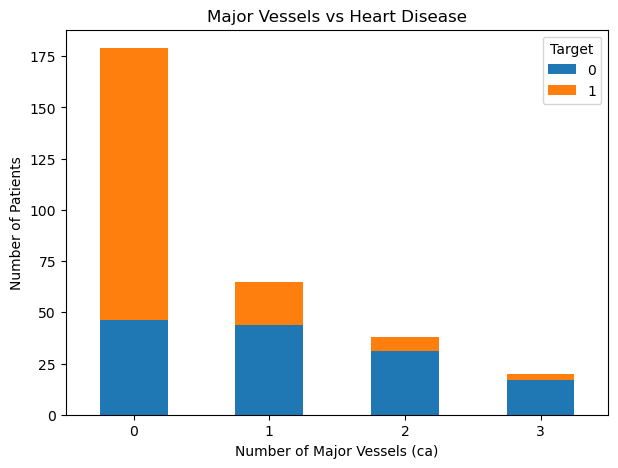

In [109]:
ca_target.plot(kind='bar', stacked=True, figsize=(7,5))
plt.title('Major Vessels vs Heart Disease')
plt.xlabel('Number of Major Vessels (ca)')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(title='Target')
plt.show()

In [110]:
# percentage of target = 1 for each number of vessels
df.groupby('ca')['target'].mean() * 100

ca
0    74.301676
1    32.307692
2    18.421053
3    15.000000
Name: target, dtype: float64

**Insight:** This is a strong relationship. **74%** of patients with 0 vessels have target = 1, but it drops to **32%** with 1 vessel, **18%** with 2 and **15%** with 3 vessels. The number of vessels clearly separates the two groups (see the note in section 3.7 about the direction of the target).

## Medium Q7. What is the average oldpeak value for patients with different types of chest pain?

In [113]:
oldpeak_cp = df.groupby('cp')['oldpeak'].mean()
oldpeak_cp

cp
0    1.383217
1    0.316000
2    0.806977
3    1.391304
Name: oldpeak, dtype: float64

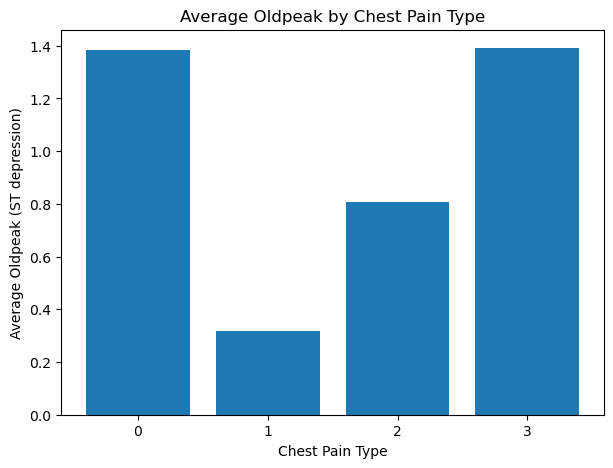

In [114]:
plt.figure(figsize=(7,5))
plt.bar(oldpeak_cp.index.astype(str), oldpeak_cp.values)
plt.title('Average Oldpeak by Chest Pain Type')
plt.xlabel('Chest Pain Type')
plt.ylabel('Average Oldpeak (ST depression)')
plt.show()

**Insight:** Chest pain types **0** (1.38) and **3** (1.39) have the highest average oldpeak, while types 1 (0.32) and 2 (0.81) are much lower. A higher oldpeak means more ST depression during exercise, so patients with chest pain type 0 (which is also the biggest group) show the strongest ECG stress signs and should be checked carefully. Type 3 has only 23 patients, so that number is less reliable.

## Medium Q8. Analyze the distribution of thalassemia types (thal) among patients.

In [117]:
thal_target = pd.crosstab(df['thal'], df['target'])
thal_target

target,0,1
thal,,
1,12,6
2,37,130
3,89,28


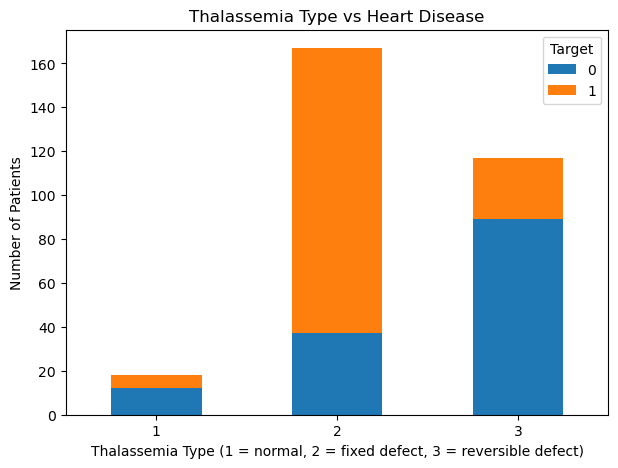

In [118]:
thal_target.plot(kind='bar', stacked=True, figsize=(7,5))
plt.title('Thalassemia Type vs Heart Disease')
plt.xlabel('Thalassemia Type (1 = normal, 2 = fixed defect, 3 = reversible defect)')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(title='Target')
plt.show()

In [119]:
df.groupby('thal')['target'].mean() * 100

thal
1    33.333333
2    77.844311
3    23.931624
Name: target, dtype: float64

**Insight:** Type 2 is the most common (167 patients), then type 3 (117) and type 1 (18). Among type 2 patients **78%** have target = 1, while among type 3 (reversible defect) only **24%** do. So thalassemia type is a strong separator of the two groups (again, see the note in section 3.7 on the direction).

## Medium Q9. What are the most common combinations of risk factors in patients with target = 1?

In [122]:
combos = (df[df['target'] == 1]
          .groupby(['cp', 'fbs', 'exang', 'thal'])
          .size()
          .reset_index(name='counts')
          .sort_values(by='counts', ascending=False))
combos.head(8)

,cp,fbs,exang,thal,counts
14,2,0,0,2,42
8,1,0,0,2,30
1,0,0,0,2,23
18,2,1,0,2,10
4,0,0,1,2,6
15,2,0,0,3,6
22,3,0,0,2,5
16,2,0,1,2,4


**Insight:** The most common combination is chest pain type **2**, fasting blood sugar **0**, angina **0** and thalassemia type **2** with **42 patients**. The top 3 combinations together cover 95 of the 164 patients, so a few typical profiles describe a large part of the group, and prevention programs can be designed around them.

## Medium Q10. Pairwise comparison of clinical measurements for patients with and without heart disease

In [125]:
df[df['target'] == 1][num_cols].describe().round(2)

,age,trestbps,chol,thalach,oldpeak
count,164.00,164.00,164.00,164.00,164.00
mean,52.59,129.25,242.64,158.38,0.59
std,9.51,16.20,53.46,19.20,0.78
min,29.00,94.00,126.00,96.00,0.00
25%,44.75,120.00,208.75,148.75,0.00
50%,52.00,130.00,234.50,161.00,0.20
75%,59.00,140.00,267.25,172.00,1.02
max,76.00,180.00,564.00,202.00,4.20


In [126]:
df[df['target'] == 0][num_cols].describe().round(2)

,age,trestbps,chol,thalach,oldpeak
count,138.00,138.00,138.00,138.0,138.00
mean,56.60,134.40,251.09,139.1,1.59
std,7.96,18.73,49.45,22.6,1.30
min,35.00,100.00,131.00,71.0,0.00
25%,52.00,120.00,217.25,125.0,0.60
50%,58.00,130.00,249.00,142.0,1.40
75%,62.00,144.75,283.00,156.0,2.50
max,77.00,200.00,409.00,195.0,6.20


In [127]:
mean_compare = df.groupby('target')[num_cols].mean().round(2)
mean_compare

,age,trestbps,chol,thalach,oldpeak
target,,,,,
0,56.60,134.40,251.09,139.10,1.59
1,52.59,129.25,242.64,158.38,0.59


The measurements are on different scales, so I use the normalized data for a fair chart.

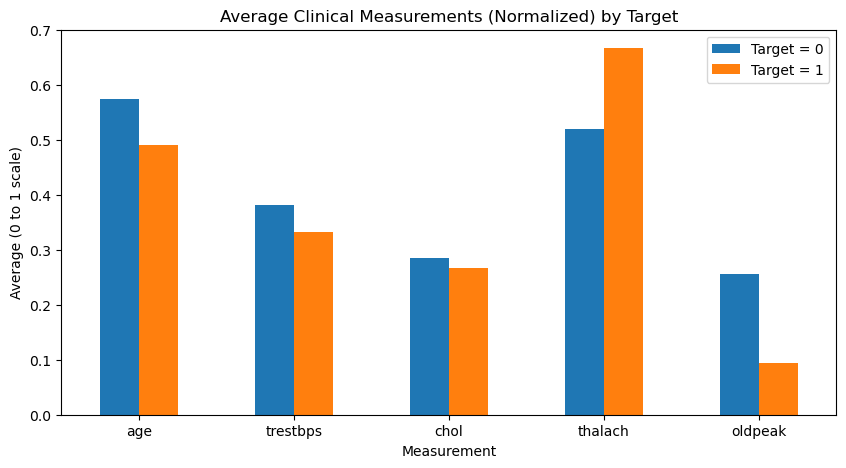

In [129]:
norm_means = df_norm.groupby('target')[num_cols].mean().T
norm_means.columns = ['Target = 0', 'Target = 1']

norm_means.plot(kind='bar', figsize=(10,5))
plt.title('Average Clinical Measurements (Normalized) by Target')
plt.xlabel('Measurement')
plt.ylabel('Average (0 to 1 scale)')
plt.xticks(rotation=0)
plt.show()

**Insight:** The two groups are most different in **maximum heart rate** (158 vs 139 bpm) and **oldpeak** (0.59 vs 1.59), and they also differ in **age** (52.6 vs 56.6). Blood pressure (129 vs 134) and cholesterol (243 vs 251) are almost the same in both groups. (The first number is target = 1 and the second is target = 0.)

# Advanced Level Questions

## Advanced Q1. What is the effect of combining multiple risk factors (age, cholesterol, blood pressure) on heart disease?

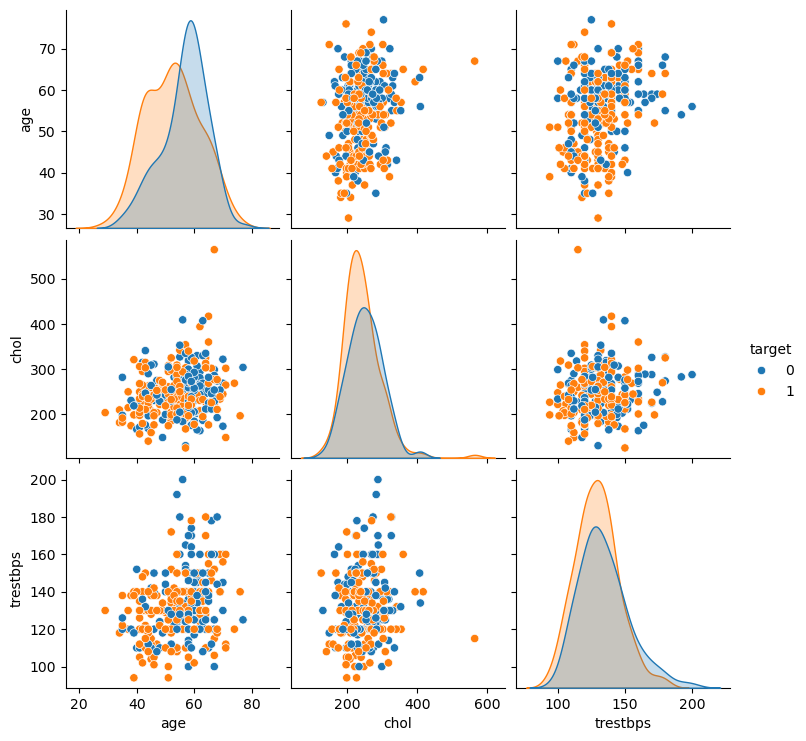

In [133]:
sns.pairplot(df, hue='target', vars=['age', 'chol', 'trestbps'])
plt.show()

The pair plot does not show a clear separation. So I try a simple risk count: one point for each of these - age above the median, cholesterol above the median and blood pressure above the median - and check the share of target = 1 patients for each count.

In [135]:
df['risk_count'] = ((df['age'] > df['age'].median()).astype(int) +
                    (df['chol'] > df['chol'].median()).astype(int) +
                    (df['trestbps'] > df['trestbps'].median()).astype(int))

risk_target = df.groupby('risk_count')['target'].agg(['mean', 'count'])
risk_target['mean'] = (risk_target['mean'] * 100).round(1)
risk_target

,mean,count
risk_count,,
0,69.0,58
1,66.7,99
2,41.6,101
3,36.4,44


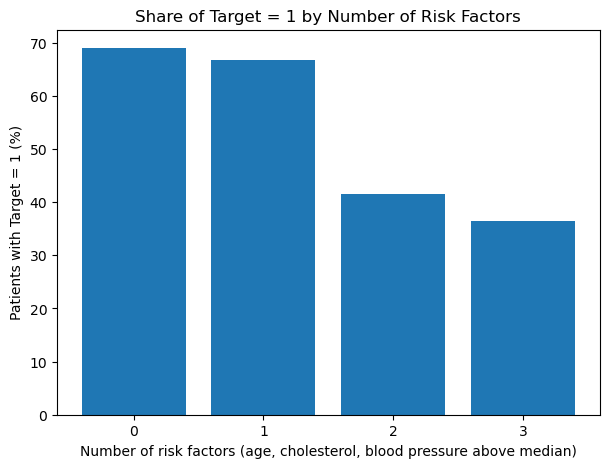

In [136]:
plt.figure(figsize=(7,5))
plt.bar(risk_target.index.astype(str), risk_target['mean'])
plt.title('Share of Target = 1 by Number of Risk Factors')
plt.xlabel('Number of risk factors (age, cholesterol, blood pressure above median)')
plt.ylabel('Patients with Target = 1 (%)')
plt.show()

**Insight:** The pair plot shows a lot of overlap between the two groups, so these three measurements alone cannot separate them. The risk count shows the same: the share of target = 1 patients goes from **69%** with no risk factor to **36%** when all three are above the median. The three factors together have a visible effect (older age, higher cholesterol and higher blood pressure go together with a change in the share), but each one is only a small part of the full picture.

## Advanced Q2. Which clinical measurement has the strongest correlation with heart disease?

In [139]:
corr_target = df.drop(columns=['sex_label', 'age_group', 'risk_count']).corr()['target'].sort_values(ascending=False)
corr_target

target      1.000000
cp          0.432080
thalach     0.419955
slope       0.343940
restecg     0.134874
fbs        -0.026826
chol       -0.081437
trestbps   -0.146269
age        -0.221476
sex        -0.283609
thal       -0.362313
oldpeak    -0.429146
exang      -0.435601
ca         -0.463886
Name: target, dtype: float64

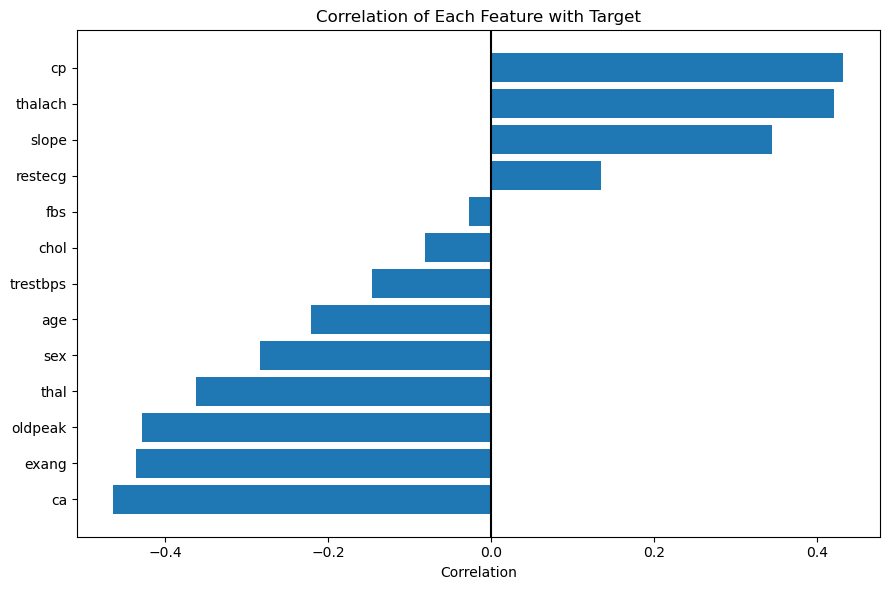

In [140]:
corr_plot = corr_target.drop('target').sort_values()

plt.figure(figsize=(9,6))
plt.barh(corr_plot.index, corr_plot.values)
plt.axvline(0, color='black')
plt.title('Correlation of Each Feature with Target')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

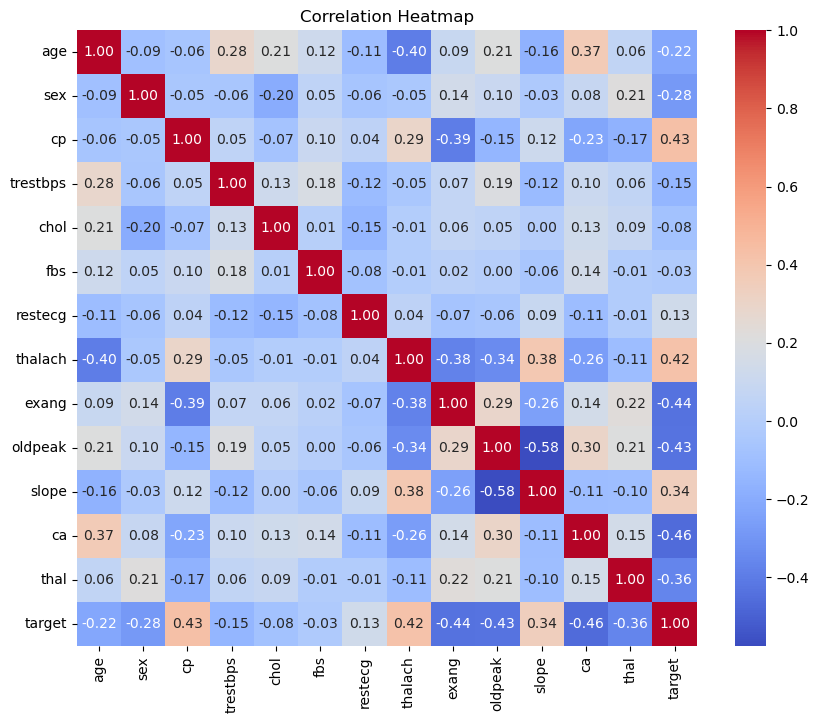

In [141]:
plt.figure(figsize=(10,8))
sns.heatmap(df.drop(columns=['sex_label', 'age_group', 'risk_count']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

**Insight:** The strongest correlations with target are **ca** (-0.46), **exang** (-0.44), **cp** (0.43) and **oldpeak** (-0.43), followed by `thalach`. Cholesterol (-0.08) and fasting blood sugar (-0.03) are almost unrelated to the target. No single measurement has a very strong correlation (all are below 0.5), so heart disease depends on a combination of factors.

## Advanced Q3. Logistic regression to predict heart disease

I use all 13 features. First I split the data into 80% train and 20% test, and I scale the features so that the coefficients can be compared with each other.

In [145]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

features = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
            'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

X = df[features]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [146]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)

print('Train accuracy:', round(model.score(X_train_s, y_train), 3))
print('Test accuracy :', round(accuracy_score(y_test, y_pred), 3))

Train accuracy: 0.88
Test accuracy : 0.803


In [147]:
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

[[22  6]
 [ 6 27]]

              precision    recall  f1-score   support

           0       0.79      0.79      0.79        28
           1       0.82      0.82      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



In [148]:
# 5-fold cross validation, to check the result is not just luck of one split
cv_scores = cross_val_score(LogisticRegression(max_iter=1000), StandardScaler().fit_transform(X), y, cv=5)
print('Cross validation accuracy for each fold:', cv_scores.round(3))
print('Average:', round(cv_scores.mean(), 3))

Cross validation accuracy for each fold: [0.852 0.82  0.95  0.783 0.817]
Average: 0.844


In [149]:
coefficients = pd.Series(model.coef_[0], index=features).sort_values()
coefficients

ca         -1.160788
sex        -0.900116
thal       -0.563468
exang      -0.500133
trestbps   -0.423421
chol       -0.293485
oldpeak    -0.268047
fbs         0.037138
restecg     0.167834
age         0.206788
slope       0.409075
thalach     0.873637
cp          0.941881
dtype: float64

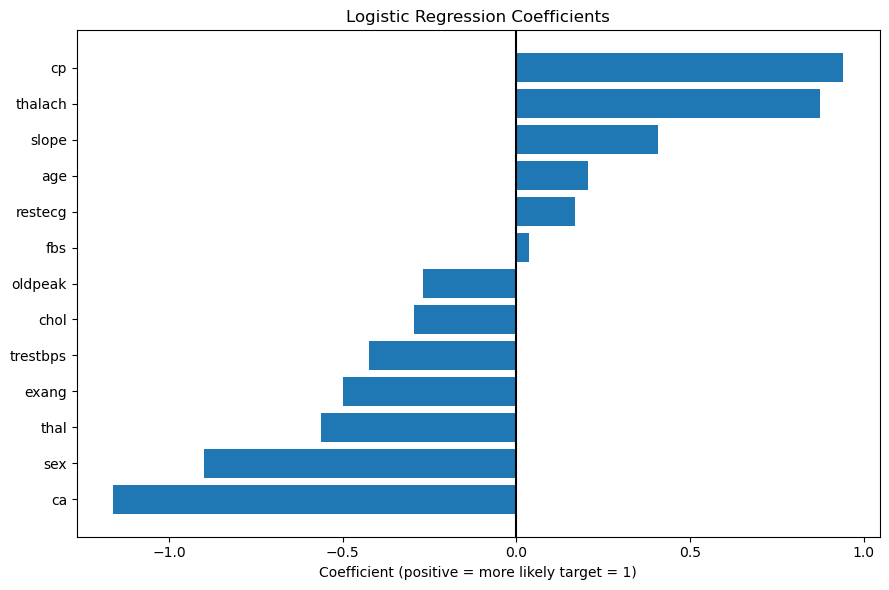

In [150]:
plt.figure(figsize=(9,6))
plt.barh(coefficients.index, coefficients.values)
plt.axvline(0, color='black')
plt.title('Logistic Regression Coefficients')
plt.xlabel('Coefficient (positive = more likely target = 1)')
plt.tight_layout()
plt.show()

**Insight:** The model has a test accuracy of **80%**, and the 5-fold cross validation average is **84%**, so the result holds up (the 5 folds are between 78% and 95%, so it does vary a bit on such a small data set) and the model is better than guessing (about 54% if we always predict the bigger group). The most important features are **ca**, **cp**, **sex** and **thalach**. Fasting blood sugar (0.04), age (0.21) and cholesterol (-0.29) have the smallest effects. This is a simple model on a small data set, so it is only for learning and **not for real medical decisions**.

## Advanced Q4. How do the values of the slope vary with different chest pain types?

In [153]:
slope_cp = pd.crosstab(df['cp'], df['slope'])
slope_cp

slope,0,1,2
cp,,,
0,11,84,48
1,2,12,36
2,5,33,48
3,3,11,9


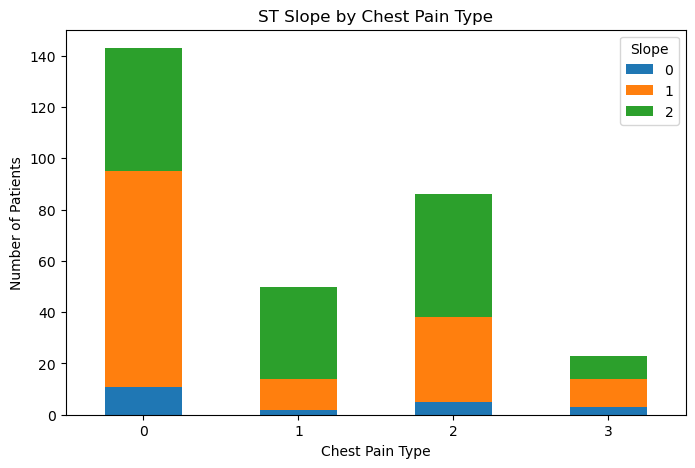

In [154]:
slope_cp.plot(kind='bar', stacked=True, figsize=(8,5))
plt.title('ST Slope by Chest Pain Type')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(title='Slope')
plt.show()

In [155]:
(pd.crosstab(df['cp'], df['slope'], normalize='index') * 100).round(1)

slope,0,1,2
cp,,,
0,7.7,58.7,33.6
1,4.0,24.0,72.0
2,5.8,38.4,55.8
3,13.0,47.8,39.1


**Insight:** Slope 0 is rare for all chest pain types. Patients with chest pain type 0 mostly have slope 1 (**59%**) and only 34% have slope 2, while types 1 and 2 mostly have slope 2 (**72%** and **56%**). Type 3 is mixed (48% slope 1 and 39% slope 2) and has few patients. So the ECG slope pattern is different for type 0 chest pain, which fits with the higher oldpeak we saw for type 0.

## Advanced Q5. Survival rates of patients with different thalassemia types over a period

This question **cannot be answered with this dataset**. There is no survival, follow-up or date column, so we do not know what happened to the patients over time and cannot calculate a survival rate. The line plot in the hint (age vs thal) would not show survival either.

What I can do is show how the share of patients with target = 1 differs by thalassemia type, and how it changes with age, as the closest thing the data allows.

In [159]:
thal_rate = df.groupby('thal')['target'].agg(['mean', 'count'])
thal_rate['mean'] = (thal_rate['mean'] * 100).round(1)
thal_rate

,mean,count
thal,,
1,33.3,18
2,77.8,167
3,23.9,117


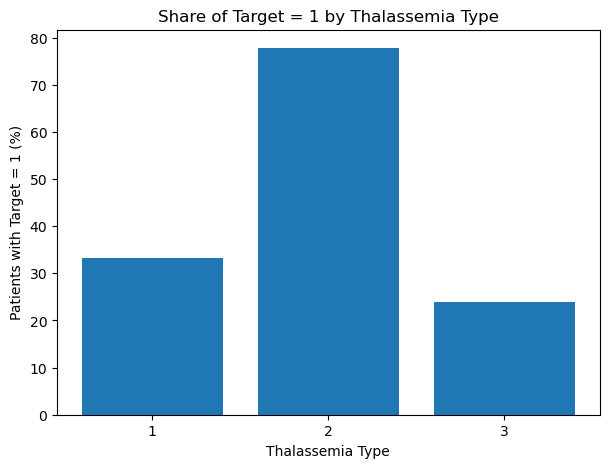

In [160]:
plt.figure(figsize=(7,5))
plt.bar(thal_rate.index.astype(str), thal_rate['mean'])
plt.title('Share of Target = 1 by Thalassemia Type')
plt.xlabel('Thalassemia Type')
plt.ylabel('Patients with Target = 1 (%)')
plt.show()

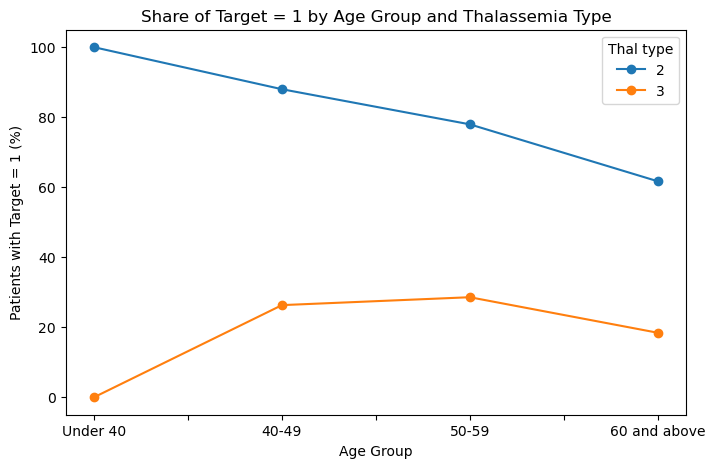

In [161]:
# by age group, only for types 2 and 3 (type 1 has too few patients)
age_thal = df[df['thal'].isin([2, 3])].groupby(['age_group', 'thal'], observed=True)['target'].mean().unstack() * 100

age_thal.plot(marker='o', figsize=(8,5))
plt.title('Share of Target = 1 by Age Group and Thalassemia Type')
plt.xlabel('Age Group')
plt.ylabel('Patients with Target = 1 (%)')
plt.legend(title='Thal type')
plt.show()

**Insight:** Survival cannot be measured here. The closest result is that **78%** of type 2 patients have target = 1 against **24%** of type 3 patients, and type 1 has only 18 patients so it cannot be judged. The line chart shows that type 2 stays higher than type 3 in all age groups. To study survival, we would need follow-up data with dates and outcomes.

# Key Findings

- The data has **302 unique patients** (723 duplicate rows were removed). The average patient is **54 years** old, and **68%** are male.
- The average resting blood pressure is **132 mm Hg** and the average cholesterol is **246 mg/dl** - both above the normal level. 32% of patients have a high blood pressure and 51% have a high cholesterol.
- 33% of patients get angina during exercise, and 15% have a high fasting blood sugar.
- The features most related to the target are **chest pain type, exercise-induced angina, ST depression (oldpeak), number of major vessels, maximum heart rate and thalassemia type**.
- Cholesterol, blood pressure, age and fasting blood sugar are only weakly related to the target in this data.
- A simple logistic regression model reaches about **80%** test accuracy (84% in cross validation).
- The target column looks reversed compared to the data dictionary (see section 3.7), so the direction of the findings must be confirmed.

# Recommendations

1. **Confirm the coding of the target column** with the cardiology institute before using any of these findings for decisions, because the data does not match the dictionary for several well-known signs.
2. **Screen older and middle-aged patients** (50 and above) for blood pressure and cholesterol, because the average patient is already above the normal level for both.
3. **Give supervised, low-intensity exercise plans** to patients who get angina during exercise, since about 1 in 3 patients has it.
4. **Look at the ECG signs together** - chest pain type, oldpeak, ST slope, number of vessels and maximum heart rate showed the strongest links, so they should be reviewed together and not one at a time.
5. **Prioritize patients with 2 or more vessels** and patients with a reversible defect (thal = 3) for further tests and specialist care, after the target coding is confirmed.
6. **Keep lifestyle advice for everyone.** Cholesterol and blood sugar did not separate the groups in this data, but they are known medical risk factors and many patients are above normal levels.
7. **Use a simple risk score** (such as the number of risk factors) to flag high-risk patients early, and improve it later with a better model.
8. **Collect better data:** more patients, follow-up outcomes over time, and lifestyle details like smoking, diet and exercise habits.

# Conclusion

From this analysis I found that heart disease in this data is not explained by one single measurement. The strongest signs come from the **exercise test and ECG results** (chest pain type, angina, ST depression, maximum heart rate, number of vessels and thalassemia type), while the common risk factors like cholesterol, blood pressure and blood sugar are only weakly related. A simple logistic regression model can use these measurements to separate the two groups with good accuracy.

**Limitations:**
- The original file had 723 duplicate rows, so only **302 unique patients** are really available, which is a small sample.
- The `target` column seems to be coded opposite to the data dictionary, so the direction of the findings needs to be confirmed.
- There is no survival or follow-up data, so survival analysis was not possible.
- The data shows relationships, not cause and effect.

*- Shubham Shah*